# Описание проекта
Вы работаете в интернет-магазине «Стримчик», который продаёт по всему миру компьютерные игры. Из открытых источников доступны исторические данные о продажах игр, оценки пользователей и экспертов, жанры и платформы (например, Xbox или PlayStation). Вам нужно выявить определяющие успешность игры закономерности. Это позволит сделать ставку на потенциально популярный продукт и спланировать рекламные кампании.  
  
Перед вами данные до 2016 года. Представим, что сейчас декабрь 2016 г., и вы планируете кампанию на 2017-й. Нужно отработать принцип работы с данными. Неважно, прогнозируете ли вы продажи на 2017 год по данным 2016-го или же 2027-й — по данным 2026 года.
В наборе данных попадается аббревиатура ESRB (Entertainment Software Rating Board) — это ассоциация, определяющая возрастной рейтинг компьютерных игр. ESRB оценивает игровой контент и присваивает ему подходящую возрастную категорию, например, «Для взрослых», «Для детей младшего возраста» или «Для подростков».

**Описание данных:**
- Name — название игры
- Platform — платформа
- Year_of_Release — год выпуска
- Genre — жанр игры
- NA_sales — продажи в Северной Америке (миллионы проданных копий)
- EU_sales — продажи в Европе (миллионы проданных копий)
- JP_sales — продажи в Японии (миллионы проданных копий)
- Other_sales — продажи в других странах (миллионы проданных копий)
- Critic_Score — оценка критиков (максимум 100)
- User_Score — оценка пользователей (максимум 10)
- Rating — рейтинг от организации ESRB (англ. Entertainment Software Rating Board). Эта ассоциация определяет рейтинг компьютерных игр и присваивает им подходящую возрастную категорию.
  
Данные за 2016 год могут быть неполными.

## Загрузка данных

In [1]:
# Импорт библиотек
import pandas as pd
import seaborn as sns
import numpy as np
import pingouin as pg
import scipy.stats as st
from matplotlib import pyplot as plt

sns.set_theme(
    style='whitegrid',        # стиль осей
    context='notebook',       # масштаб (notebook, talk, paper, poster)
    palette='tab10',           # цветовая палитра
    font_scale=1.1,           # масштаб шрифта
    rc={
        'figure.figsize': (12, 6),
        'axes.titlesize': 14,
        'axes.labelsize': 12,
        'grid.alpha': 0.3,
        'figure.dpi': 110
    }
)

In [2]:
# Считывание данных
data = pd.read_csv('games.csv')

In [3]:
data.head()

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


In [4]:
# Приводим называние полей к нижнему регистру
data.columns = data.columns.str.lower()

In [5]:
# Общая информация о датасете
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16713 non-null  str    
 1   platform         16715 non-null  str    
 2   year_of_release  16446 non-null  float64
 3   genre            16713 non-null  str    
 4   na_sales         16715 non-null  float64
 5   eu_sales         16715 non-null  float64
 6   jp_sales         16715 non-null  float64
 7   other_sales      16715 non-null  float64
 8   critic_score     8137 non-null   float64
 9   user_score       10014 non-null  str    
 10  rating           9949 non-null   str    
dtypes: float64(6), str(5)
memory usage: 1.4 MB


In [6]:
# Изменим тип данных в поле 'year_of_release' на Int64
data['year_of_release'] = data['year_of_release'].astype('Int64')

In [7]:
# Изменим тип данных в поле user_score на float. Заменим значение tbd(To Be Decided) на NaN
data['user_score'] = data['user_score'].replace('tbd', np.nan)
data['user_score'] = data['user_score'].astype('float')

In [8]:
# Проверим наличие пропусков
data.isna().sum()

name                  2
platform              0
year_of_release     269
genre                 2
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8578
user_score         9125
rating             6766
dtype: int64

In [9]:
# Удалим строки с пропущенными значениями в полях 'name' и 'genre'
data.dropna(subset=['name', 'genre'], inplace=True)

In [10]:
# Извлечем год выпуска из называния игры, для заполнения пропусков в поле 'year_of_release', там где это возможно
data['year_of_release'] = data['year_of_release'].fillna(data['name'].str.extract(r'(\d{4})')[0])

In [11]:
# Удалим строки, где есть про пуски во ВСЕХ указанных полях 'year_of_release', 'critic_score', 'user_score', 'rating'
data.dropna(subset=['year_of_release', 'critic_score', 'user_score', 'rating'], how='all', inplace=True)

In [12]:
# Заменим пропуски в поле rating на RP - Rating Pending(рейтинг еще не присвоен)
# Добавис расшифровку рейтингов
data['rating'] = data['rating'].fillna('RP - нет рейтинга')

rating_map = {
    'E': 'E - для всех',
    'M': 'M - 17+',
    'T': 'T - 13+',
    'E10+': 'E10+ - 10+',
    'K-A': 'K-A - 6+',
    'A0': 'A0 - 18+',
    'EC': 'E (Для всех)',
    'RP': 'RP - нет рейтинга'
}

data['rating'] = data['rating'].replace(rating_map)

In [13]:
data.isna().sum()

name                  0
platform              0
year_of_release     172
genre                 0
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8496
user_score         9043
rating                0
dtype: int64

In [14]:
# Создадим поле 'total_sales' с суммой продаж по всем регионам
data['total_sales'] = data.na_sales + data.eu_sales + data.jp_sales + data.other_sales

In [15]:
data.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E - для всех,82.54
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,RP - нет рейтинга,40.24
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E - для всех,35.52
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80.0,8.0,E - для всех,32.77
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,RP - нет рейтинга,31.38


## Исследовательский анализ данных

#### 1. Посмотрим, сколько игр выпускалось в разные годы. Важны ли данные за все периоды.

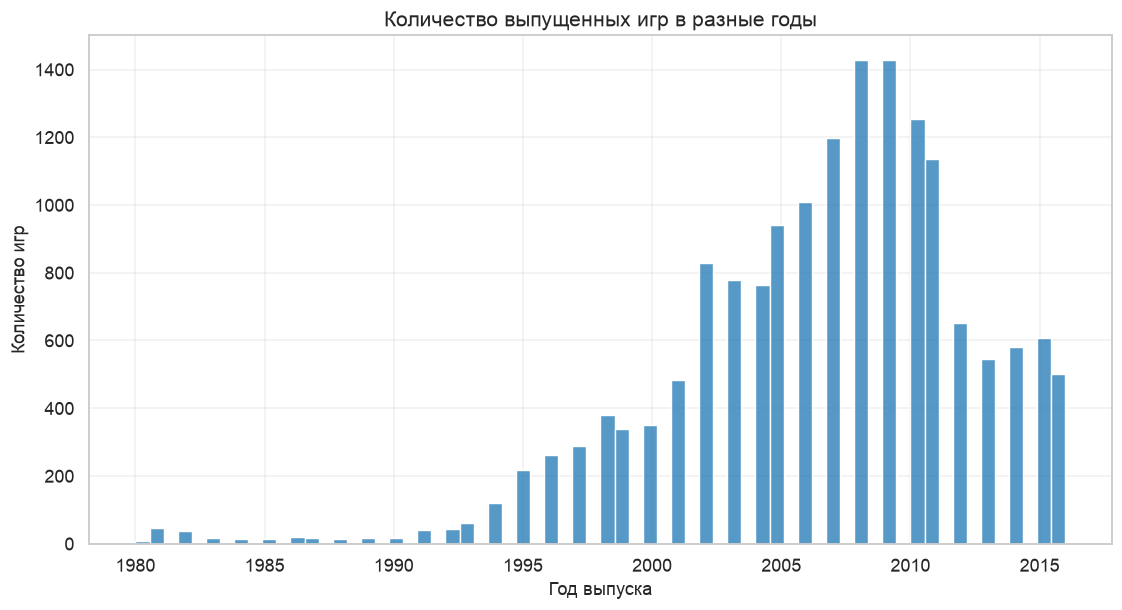

In [16]:
sns.histplot(data.year_of_release)
plt.title('Количество выпущенных игр в разные годы')
plt.xlabel('Год выпуска')
plt.ylabel('Количество игр')
plt.show()

**Вывод:**
Данные до 1990 года можно не учитыввать.

#### 2. Посмотрим, как менялись продажи по платформам.
Выберем платформы с наибольшими суммарными продажами и построим распределение по годам. Попробуем определить, за какой характерный срок появляются новые и исчезают старые платформы.

In [17]:
# Посчитаем общее количество продаж по каждой платформе
data_platform = data.groupby('platform').agg({'total_sales': 'sum'}).reset_index().sort_values('total_sales')

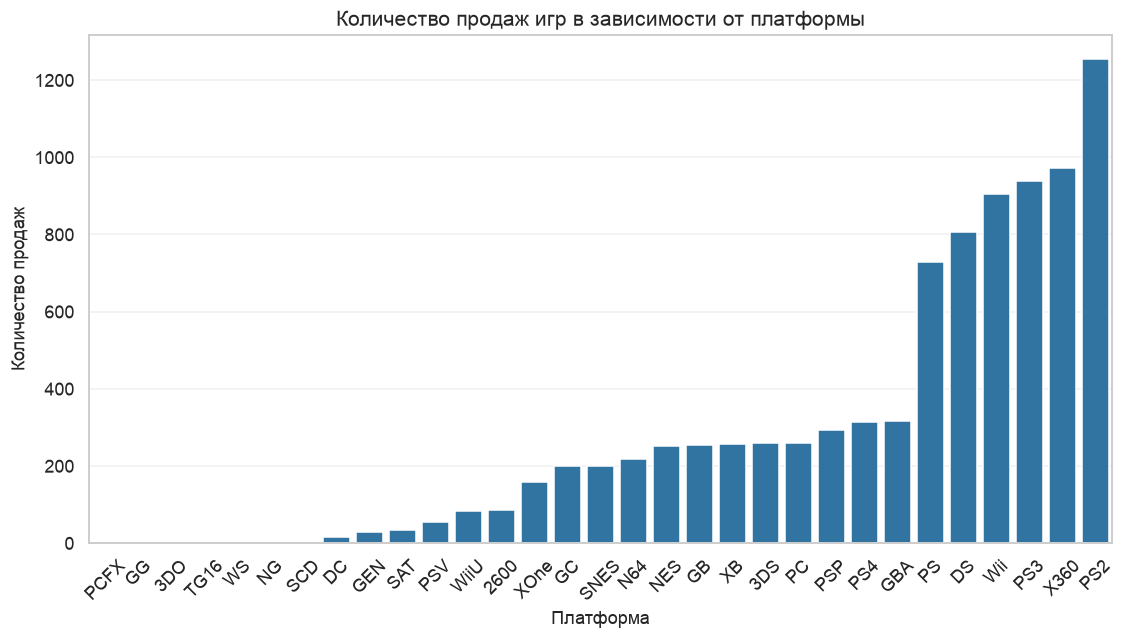

In [18]:
# Построим гисторграмму продаж по платформам
sns.barplot(data_platform, x='platform', y='total_sales')
plt.title('Количество продаж игр в зависимости от платформы')
plt.xlabel('Платформа')
plt.ylabel('Количество продаж')
plt.xticks(rotation=45)
plt.show()

**Вывод:**  
Есть разделение платформ по общему количеству продаж игр на группы: свыше 700 млн. копий, от 200 до 400 млн. копий, менее 200 млн. копий

In [19]:
# Отберем платформы с общим количеством продаж игр более 700 млн. копий
top_platform = list(data_platform[data_platform['total_sales'] > 700].platform)

top_platform_data = data[data.platform.isin(top_platform)]

In [20]:
# Посчитаем количество продаж игр по годам с учетом платформы
top_platform_sales_from_year = top_platform_data.groupby(['platform', 'year_of_release']).agg({'total_sales': 'sum'}).reset_index()

In [21]:
# Развернем таблицу
top_platform_sales_from_year.pivot_table(index='year_of_release', columns='platform', values='total_sales')

platform,DS,PS,PS2,PS3,Wii,X360
year_of_release,,,,,,
1985,0.02,NaN,NaN,NaN,NaN,NaN
1994,NaN,6.03,NaN,NaN,NaN,NaN
1995,NaN,35.96,NaN,NaN,NaN,NaN
1996,NaN,94.70,NaN,NaN,NaN,NaN
1997,NaN,136.17,NaN,NaN,NaN,NaN
1998,NaN,169.49,NaN,NaN,NaN,NaN
1999,NaN,144.53,NaN,NaN,NaN,NaN
2000,NaN,96.37,39.17,NaN,NaN,NaN
2001,NaN,35.59,166.43,NaN,NaN,NaN


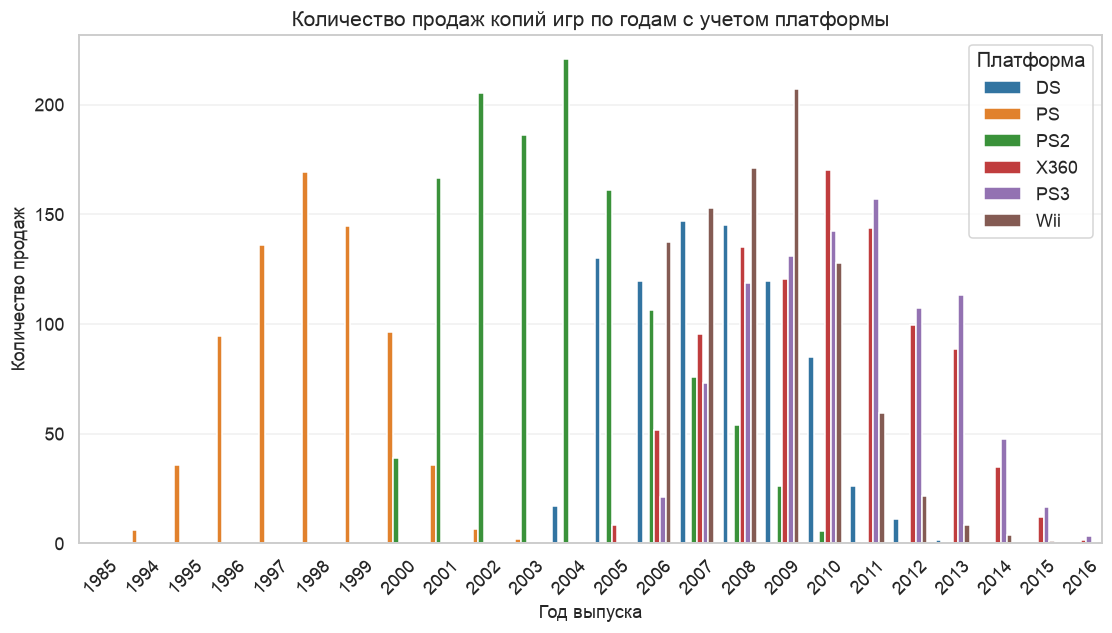

In [22]:
# Построи график для наглядности
plt.figure(figsize=(12,6))
plt.xticks(rotation=45)
sns.barplot(top_platform_sales_from_year, x='year_of_release', y='total_sales', hue='platform')
plt.title('Количество продаж копий игр по годам с учетом платформы')
plt.xlabel('Год выпуска')
plt.ylabel('Количество продаж')
plt.legend(title='Платформа')
plt.show()

**Вывод:**  
На основе данных можно сделать вывод, что средний срок жизни платформы 10 лет. Для построения компании на 2017 год нам нужны данные не позднее 2007 года.

In [23]:
# Оставим игры с 2007 года выпуска
filter_data = data[data['year_of_release'] >= 2007].copy()

#### 3. Посмотрим какие платформы лидируют по продажам, чтобы в дальнейшем отобрать несколько потенциально прибыльных платформ.

In [24]:
# Посчитаем количество продаж игр по годам с учетом платформы
sales_platform_from_year = filter_data.groupby(['platform', 'year_of_release']).agg({'total_sales': 'sum'}).reset_index()

In [25]:
# Развернем таблицу в удлбнгочитаемый вид
sales_platform_pivot = sales_platform_from_year.pivot_table(index='platform', columns='year_of_release', values='total_sales')
sales_platform_pivot

year_of_release,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016
platform,,,,,,,,,,
3DS,NaN,NaN,NaN,NaN,63.20,51.36,56.57,43.76,27.78,15.14
DC,0.02,0.04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DS,146.94,145.32,119.54,85.02,26.18,11.01,1.54,NaN,NaN,NaN
GBA,3.40,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GC,0.27,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PC,9.28,12.42,16.91,24.28,35.03,23.22,12.73,13.28,8.52,5.25
PS2,75.99,53.90,26.40,5.64,0.45,NaN,NaN,NaN,NaN,NaN
PS3,73.19,118.52,130.93,142.17,156.78,107.36,113.25,47.76,16.82,3.60
PS4,NaN,NaN,NaN,NaN,NaN,NaN,25.99,100.00,118.90,69.25


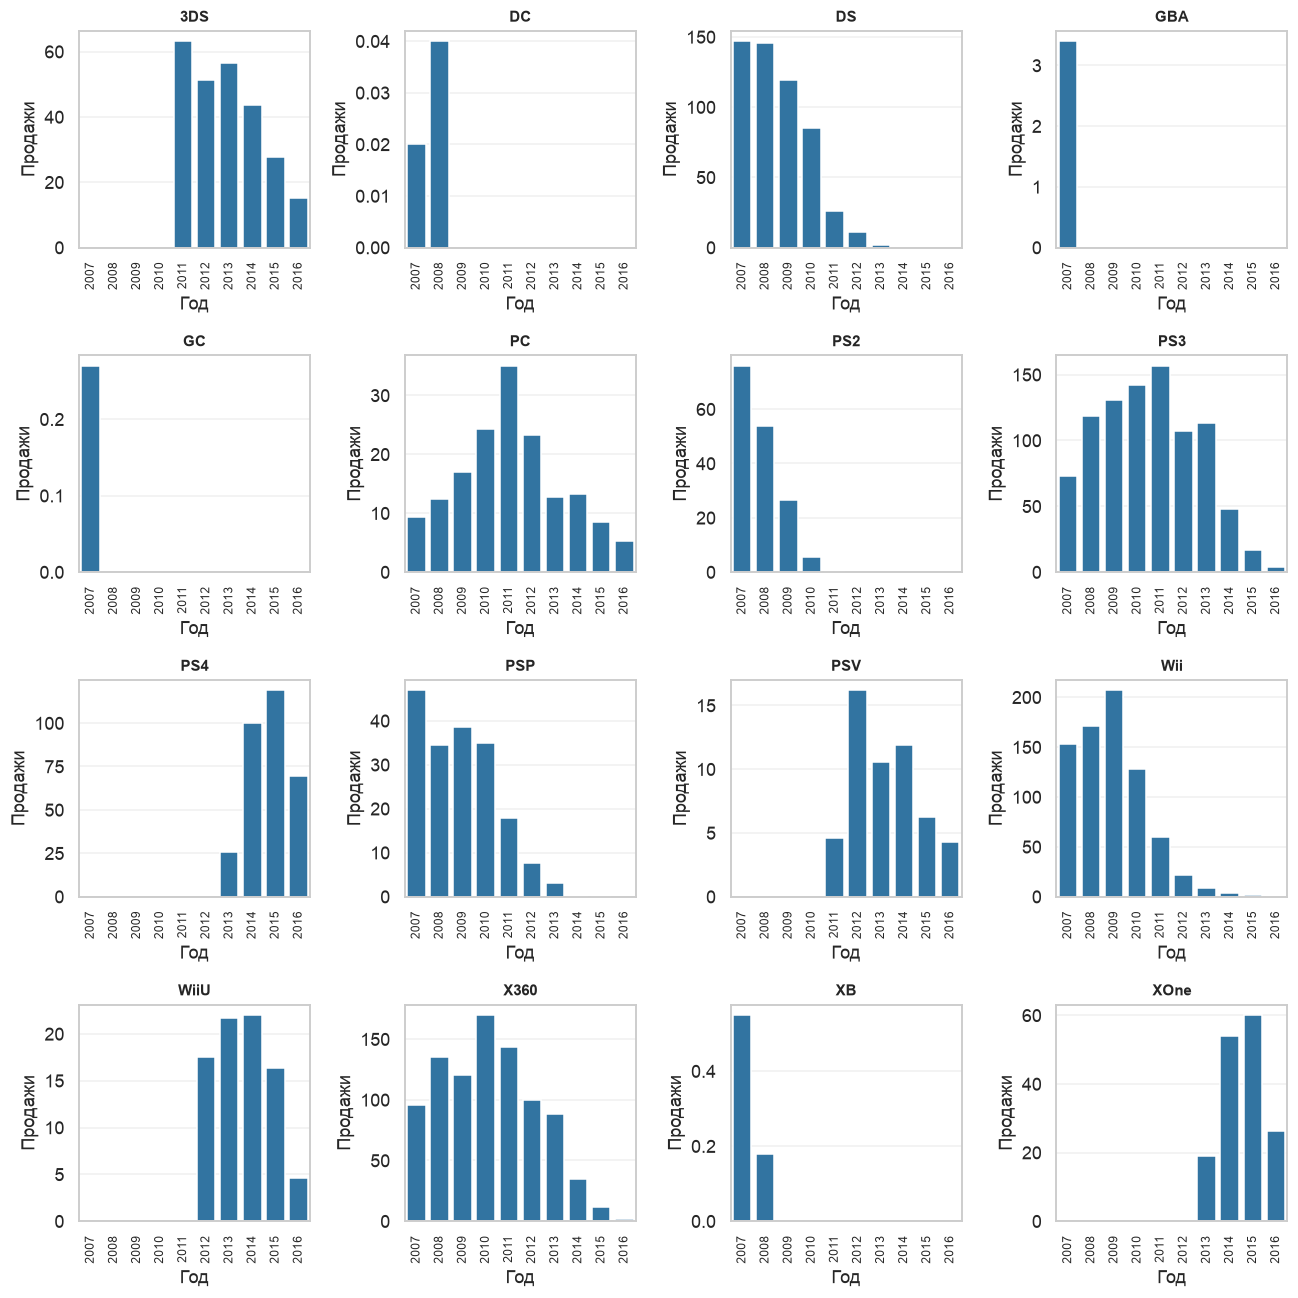

In [26]:
# Построим графики продаж по годам для каждой платформы
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
axes = axes.flatten()

for i, platform in enumerate(sales_platform_pivot.index):
    
    data = sales_platform_pivot.loc[platform]  # Series: index=годы, values=продажи
    
    sns.barplot(x=data.index, y=data.values, ax=axes[i])
    axes[i].set_title(f'{platform}', fontsize=10, fontweight='bold')
    axes[i].set_xlabel('Год')
    axes[i].set_ylabel('Продажи')
    axes[i].tick_params(axis='x', rotation=90, labelsize=8)
    axes[i].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

**Вывод:**
- На платформах DC, DS, GBA, GC, PS2, XB - последние годы продаж не было.  
- Платформы PS3, PSP, Wii, X360 - скорее всего подходят к концу 10-летнего цикла жизни платформ.  
- Отдельно стоит рассмотреть платформу PC - пик популярности приходился на 2011 год, но нельзя с уверенностью сказать, что эта платформа полностью исчезнет.
- Платформы 3DS, PSV - хоть и находятся в начале жизненого цикла, но количество продаж на этих платформах ежегодно идет на спад.
- Платформы PS4,  WiiU, XOne - находятся в начале своего жизненого цикла. Количество продаж на этих платформах стабильно или растет.

In [27]:
# Уберем DC, DS, GBA, GC, PS2, XB платформы из данных
filter_data = filter_data.query("platform not in ['DC', 'DS', 'GBA', 'GC', 'PS2', 'XB']")

#### 4. Построим график «ящик с усами» по глобальным продажам игр в разбивке по платформам.

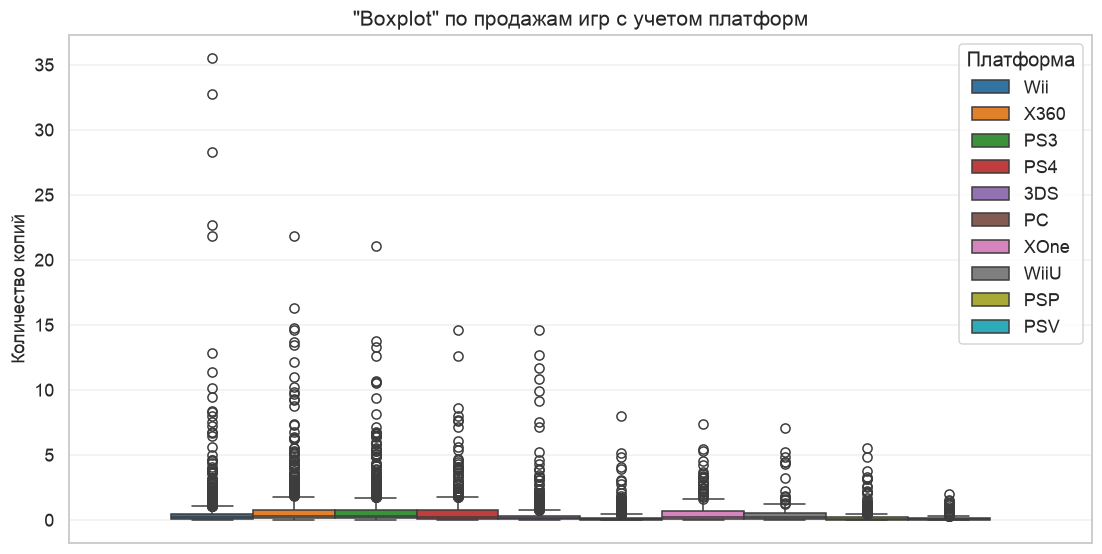

In [28]:
# График Boxplot по глобальным продажам игр в разбивке по платформам.
sns.boxplot(data=filter_data,
            y='total_sales',
            hue='platform')
plt.title('"Boxplot" по продажам игр с учетом платформ')
plt.ylabel('Количество копий')
plt.legend(title='Платформа')

**Вывод:**  
У платформы Wii было несколько популярных игр которые распродали более 20 млн. копий. У платформ X360 и PS3 было по одной такой игре.

#### 5. Посмотрим, как влияют на продажи внутри одной платформы отзывы пользователей и критиков. 
Построим диаграмму рассеяния и посчитаем корреляцию между отзывами и продажами. Для примера возьмем платформу Wii.

In [29]:
# Отберем данные по платформеп Wii
wii_platform = filter_data.query("platform == 'Wii'")

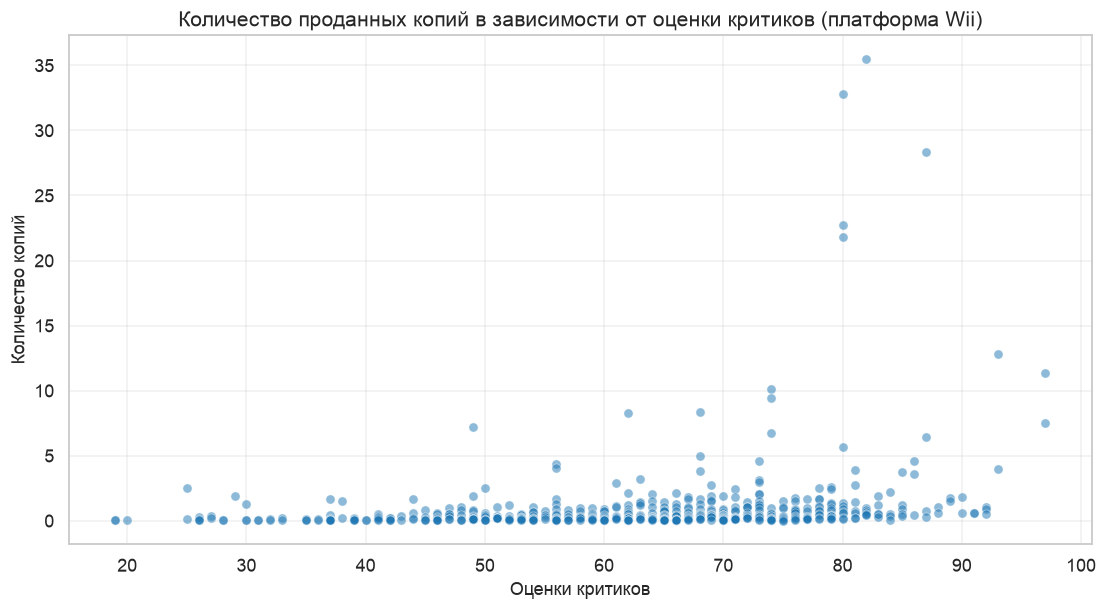

In [30]:
# Построим график зависимости продаж от оценки критиков
sns.scatterplot(data=wii_platform,
                x='critic_score',
                y='total_sales',
                alpha=0.5)
plt.title('Количество проданных копий в зависимости от оценки критиков (платформа Wii)')
plt.xlabel('Оценки критиков')
plt.ylabel('Количество копий')
plt.show()

График "прилип" к оси Х. Прологорифмируем количество продаж.

In [31]:
# Прологорифмируем данные в поле total_sales
wii_platform['log_total_sales'] = np.log(wii_platform.total_sales)

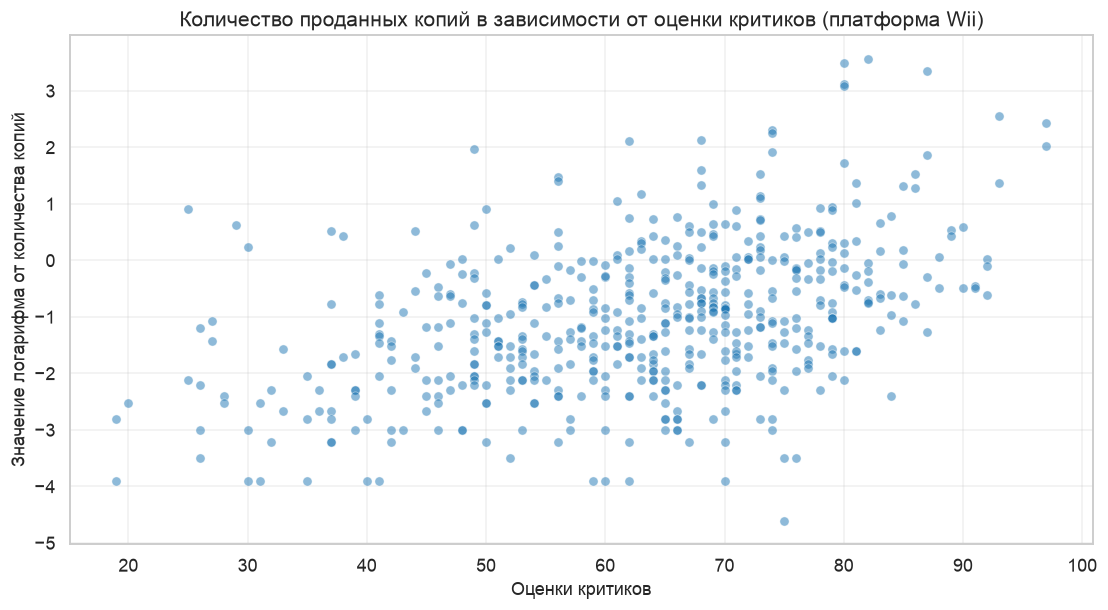

In [32]:
# Построим график зависимости логарифма продаж от оценки критиков
sns.scatterplot(data=wii_platform,
                x='critic_score',
                y='log_total_sales',
                alpha=0.5)
plt.title('Количество проданных копий в зависимости от оценки критиков (платформа Wii)')
plt.xlabel('Оценки критиков')
plt.ylabel('Значение логарифма от количества копий')
plt.show()

Видна зависимость логарифма количества продаж от оценки критиков.  

Построим такие же графики для оценок игроков.

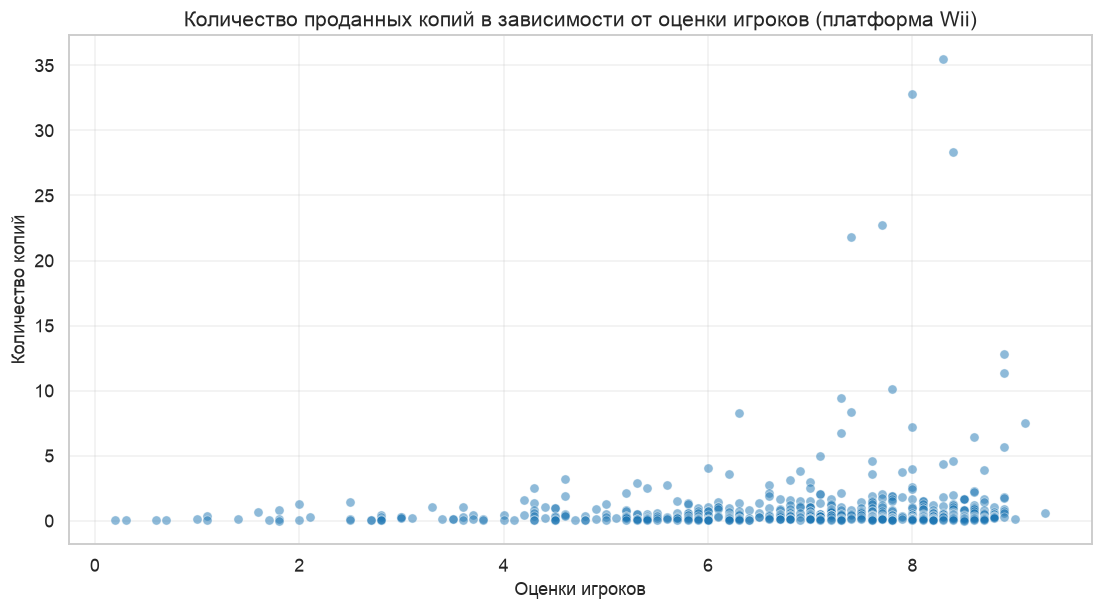

In [33]:
# Построим график зависимости продаж от оценки игроков
sns.scatterplot(data=wii_platform,
                x='user_score',
                y='total_sales',
                alpha=0.5)
plt.title('Количество проданных копий в зависимости от оценки игроков (платформа Wii)')
plt.xlabel('Оценки игроков')
plt.ylabel('Количество копий')
plt.show()

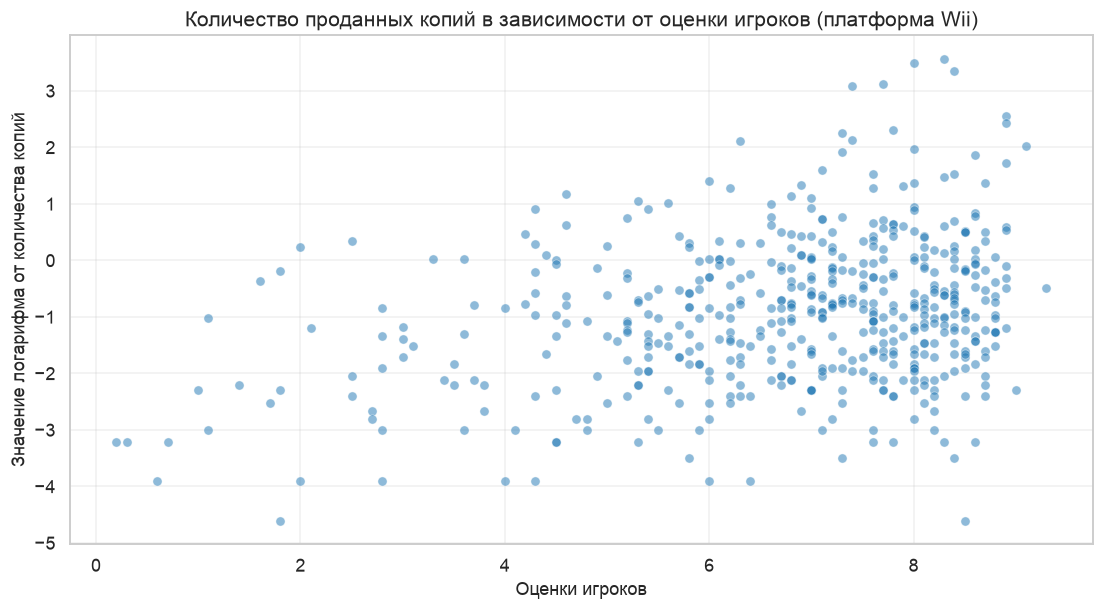

In [34]:
# Построим график зависимости логорифма продаж от оценки игроков
sns.scatterplot(data=wii_platform,
                x='user_score', 
                y='log_total_sales', 
                alpha=0.5)
plt.title('Количество проданных копий в зависимости от оценки игроков (платформа Wii)')
plt.xlabel('Оценки игроков')
plt.ylabel('Значение логарифма от количества копий')
plt.show()

На этих графиках корреляция просмаптривается сильно слабее.  
Посчитаем коэффициент корреляции количества продаж от оценок критиков и оценок игроков.

In [35]:
# Расчитываем коэфф корреляции
pg.pairwise_corr(data=wii_platform,
                 columns=[['total_sales'], ['critic_score', 'user_score']]
                )

,X,Y,method,alternative,n,r,CI95,p_unc,BF10,power
0,total_sales,critic_score,pearson,two-sided,534,0.237735,"[0.16, 0.32]",2.686391e-08,2.691e+05,0.999858
1,total_sales,user_score,pearson,two-sided,515,0.141303,"[0.06, 0.22]",1.304295e-03,9.549,0.896480


**Выводы:**  
Есть небольшая корреляция между общим количеством продаж и оценками критиков, и более слабая корреляция от оценок игроков.

Проверим корреляцию на платформах PS4, WiiU и XOne.

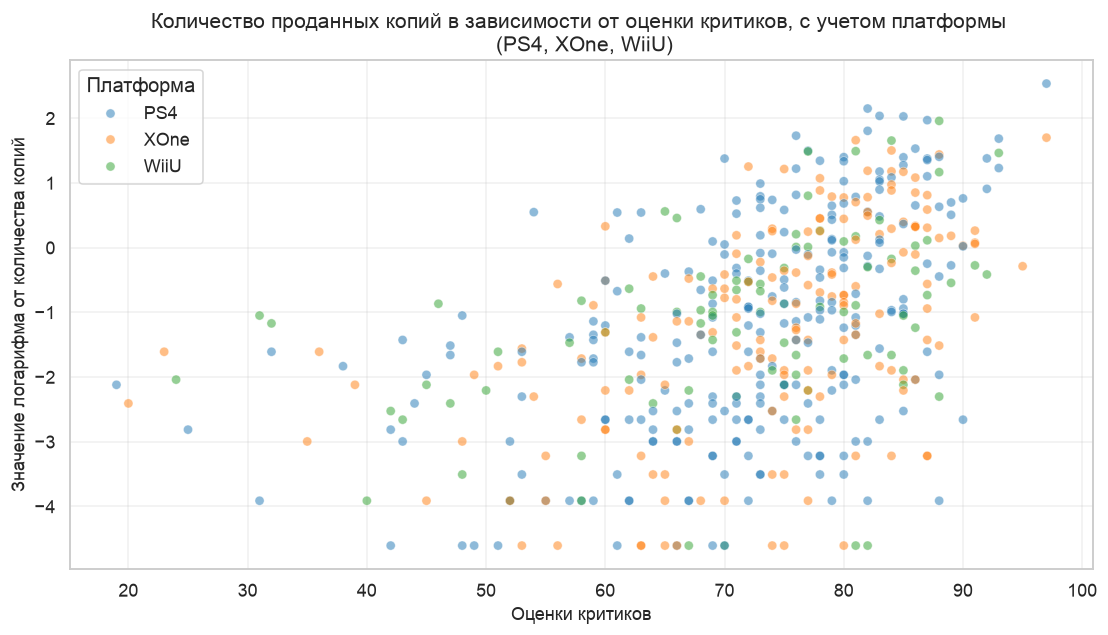

In [36]:
# Прологорифмируем количество продаж по всем платформам, добавим к продажам константу, чтобы избежать нулевых значений
filter_data['log_total_sales']= np.log(filter_data.total_sales + 10**(-10))

# Построим график логорифма количества продаж в зависимости от оценок критиков с учетом платформ
sns.scatterplot(data=filter_data.query("platform in ['PS4', 'WiiU', 'XOne']"),
                x='critic_score',
                y='log_total_sales',
                alpha=0.5,
                hue='platform')
plt.title('Количество проданных копий в зависимости от оценки критиков, с учетом платформы \n (PS4, XOne, WiiU)')
plt.xlabel('Оценки критиков')
plt.ylabel('Значение логарифма от количества копий')
plt.legend(title='Платформа')
plt.show()

In [37]:
# Посчитаем коэфф корреляции количества продаж от оценок критиков и оценок игроков для платформ PS4, XOne, WiiU
pg.pairwise_corr(data=filter_data.query("platform in ['PS4', 'WiiU', 'XOne']"),
                 columns=[['total_sales'], ['critic_score', 'user_score']]
                )

,X,Y,method,alternative,n,r,CI95,p_unc,BF10,power
0,total_sales,critic_score,pearson,two-sided,511,0.385287,"[0.31, 0.46]",1.573307e-19,2.725e+16,1.000000
1,total_sales,user_score,pearson,two-sided,539,0.028922,"[-0.06, 0.11]",5.028336e-01,0.067,0.102817


**Выводы:**  
Присутствует умеренная корреляция между оценками критиков и общим количеством продаж.

#### 6. Посмотрим на общее распределение игр по жанрам. 
Какие жанры самые прибыльные? Выделяются ли жанры с высокими и низкими продажами?

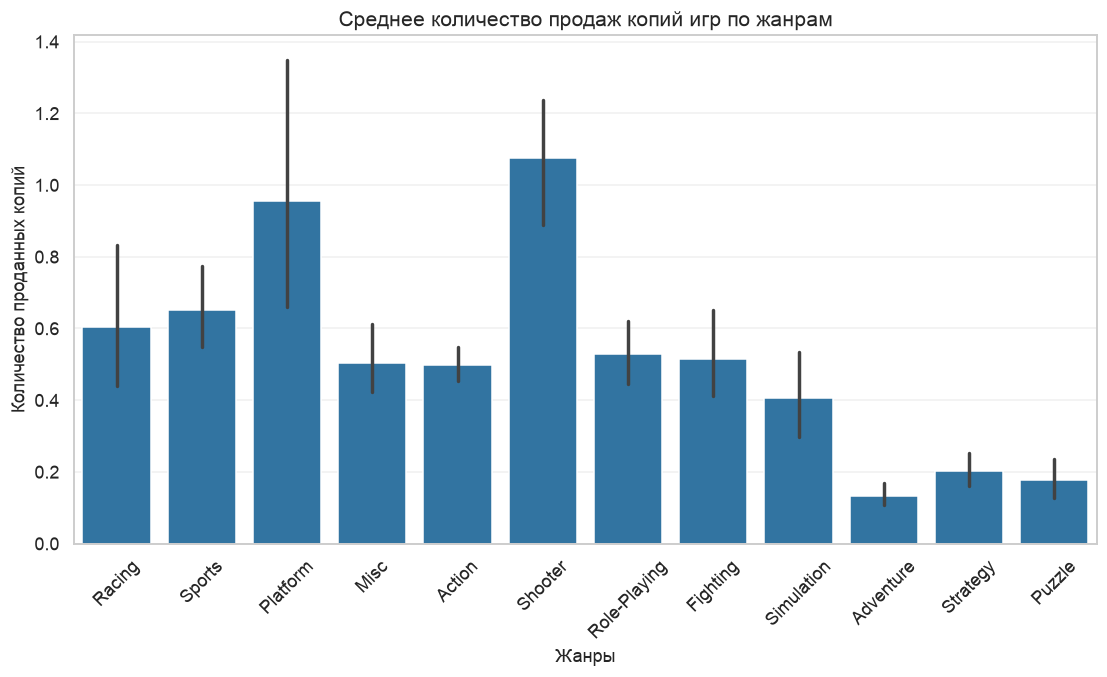

In [38]:
# Построим график среднего количества продаж на игру в зависимости от жанра
sns.barplot(data=filter_data,
             x='genre',
             y='total_sales',
             estimator='mean')
plt.title('Среднее количество продаж копий игр по жанрам')
plt.ylabel('Количество проданных копий')
plt.xlabel('Жанры')
plt.xticks(rotation=45)
plt.show()

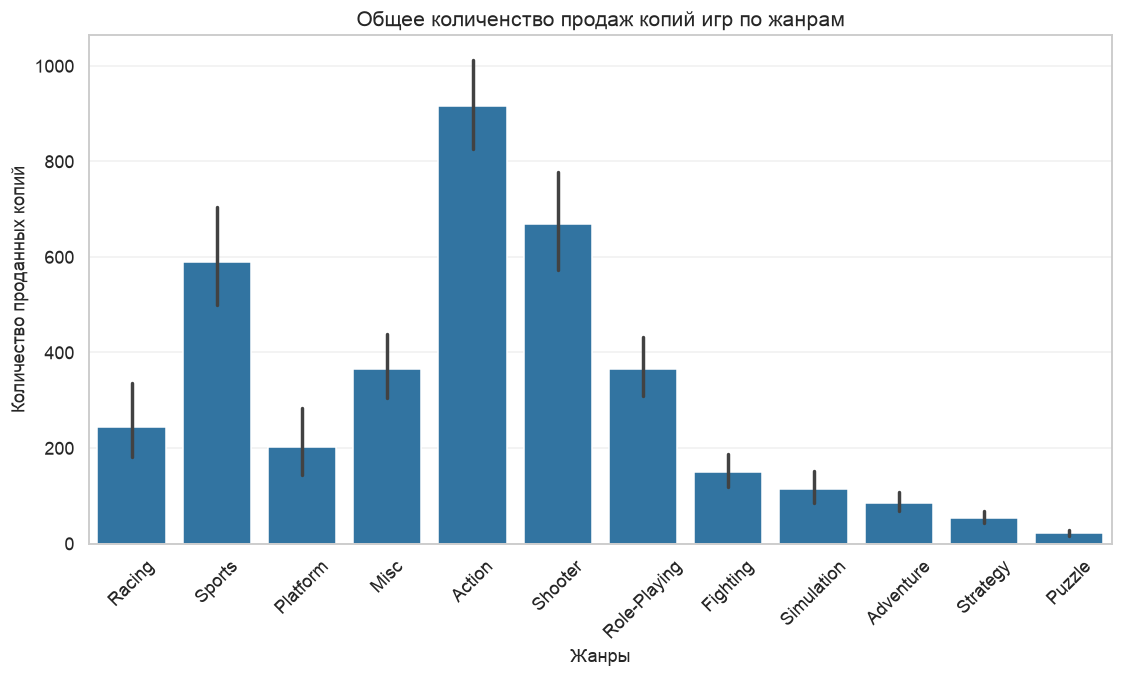

In [39]:
# Построим график общего количества продаж копий игр в зависимости от жанра
sns.barplot(data=filter_data,
             x='genre',
             y='total_sales',
             estimator='sum')
plt.title('Общее количенство продаж копий игр по жанрам')
plt.ylabel('Количество проданных копий')
plt.xlabel('Жанры')
plt.xticks(rotation=45)
plt.show()

**Выводы:**  
- На общем фоне выделяется жанр Shooter с высокими средним и общим количеством проданных копий.
- У жанра Platform высокое среднее количество проданных копий но общее количество проданных копий относительно малое.
- У жанров Sports и Action средние значения по среднему количеству проданных копий и высокие показатели по общему количеству проданных копий игр.
- Жанры Adventure, Strategy и Puzzle и имеют низкие показатели по обеим характеристикам.

## Составление портрета пользователя в зависимости от региона
Определим для пользователя каждого региона (NA, EU, JP, Other):
- Самые популярные платформы (топ-5).
- Самые популярные жанры (топ-5).
- Влияет ли рейтинг ESRB на продажи в отдельном регионе?

#### 1. Посмотрим на распределение пользователей по платформам с учетом региона.

In [40]:
# Посчитаем продажи игр по регионам с учетом платформ
platform_per_region = (filter_data
                       .groupby('platform')
                       .agg(total_sales_na=('na_sales', 'sum'),
                            total_sales_eu=('eu_sales', 'sum'),
                            total_sales_jp=('jp_sales', 'sum'),
                            total_sales_other=('other_sales', 'sum')
                           )
                       .reset_index()
                       .sort_values('total_sales_na')
                       )
                       
long_platform_per_region = pd.wide_to_long(platform_per_region,
                       stubnames='total_sales',
                       i='platform',
                       j='region',
                       sep='_',
                       suffix='.+')

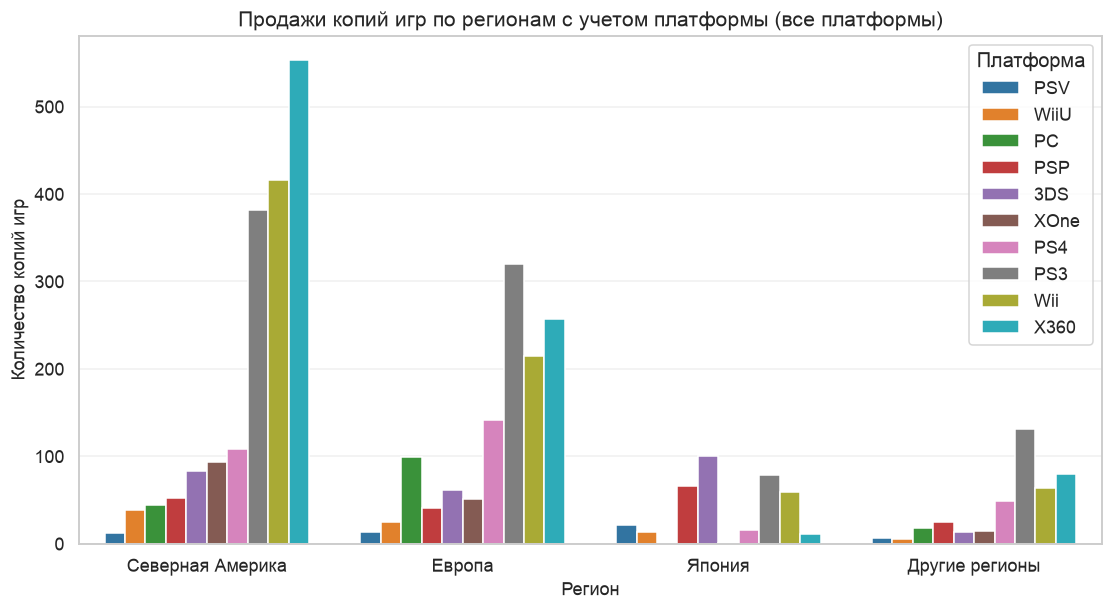

In [41]:
sns.barplot(long_platform_per_region, x='region', y='total_sales', hue='platform')
plt.title('Продажи копий игр по регионам с учетом платформы (все платформы)')
plt.xlabel('Регион')
plt.ylabel('Количество копий игр')
plt.legend(title='Платформа')
plt.xticks(ticks=range(4), labels=['Северная Америка', 'Европа', 'Япония', 'Другие регионы'])
plt.show()

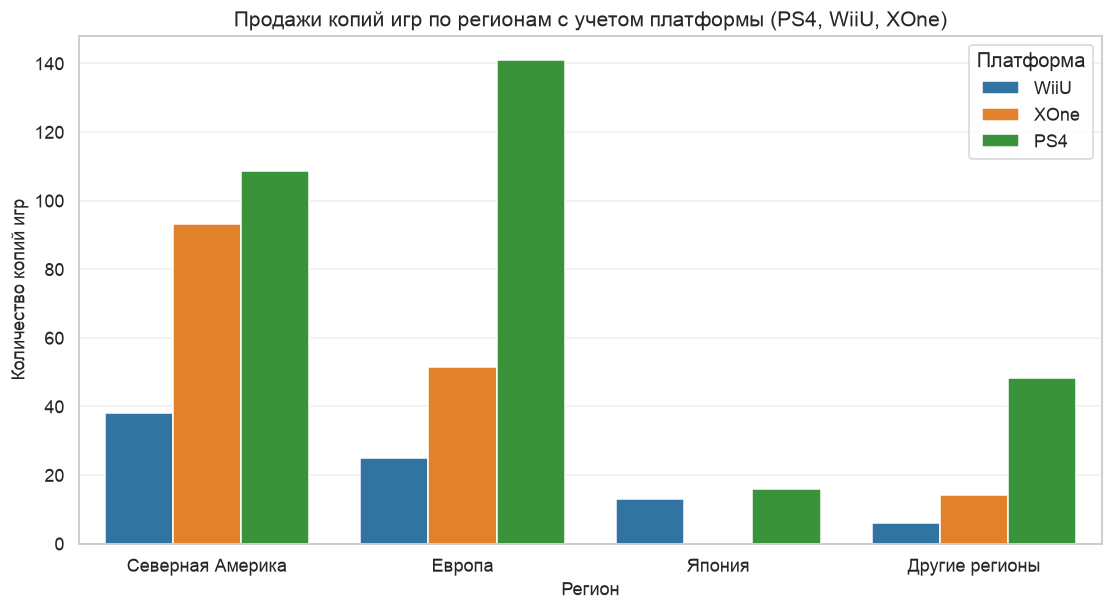

In [42]:
# Построим тот же график, но для перспективных платформ
long_top_platform = long_platform_per_region.query("platform in ['PS4', 'WiiU', 'XOne']")

sns.barplot(long_top_platform, x='region', y='total_sales', hue='platform')
plt.title('Продажи копий игр по регионам с учетом платформы (PS4, WiiU, XOne)')
plt.xlabel('Регион')
plt.ylabel('Количество копий игр')
plt.legend(title='Платформа')
plt.xticks(ticks=range(4), labels=['Северная Америка', 'Европа', 'Япония', 'Другие регионы'])
plt.show()

**Вывод:**
- Для Северной Америки большой популяностью пользуется платформы PS4, XOne, PS3, Wii и с отрывом X360. Из перпективных платформ выделяются PS4 и XOne.
- Для Европы большой популяностью пользуется платформы PC, PS4, Wii, X360 и с небольшим отрывом PS3. Из перпективных платформ явным лидером является PS4.
- Для Японии большой популяностью пользуется платформы PSP, PS3, Wii и 3DS. Из перпективных платформ выделяются WiiU и PS4.
- В остальных регионах большой популяностью пользуется платформы PS4, Wii, X360 и с небольшим отрывом PS3. Из перпективных платформ явным лидером является PS4.

#### 2. Посмотрим на распределение пользователей по жанрам с учетом региона.¶

In [43]:
# Посчитаем продажи игр по регионам с учетом жанра
# Уберем не популярные жанры 'Adventure', 'Strategy', 'Puzzle'
genre_per_region = (filter_data.query("genre not in ['Adventure', 'Strategy', 'Puzzle']")
                       .groupby('genre')
                       .agg(total_sales_na=('na_sales', 'sum'),
                            total_sales_eu=('eu_sales', 'sum'),
                            total_sales_jp=('jp_sales', 'sum'),
                            total_sales_other=('other_sales', 'sum')
                           )
                       .reset_index()
                       .sort_values('total_sales_na')
                       )
                       
long_genre = pd.wide_to_long(genre_per_region,
                             stubnames='total_sales',
                             i='genre',
                             j='region',
                             sep='_',
                             suffix='.+')
long_genre.head()

,,total_sales
genre,region,
Simulation,na,46.23
Fighting,na,75.64
Platform,na,95.79
Racing,na,100.95
Role-Playing,na,138.75


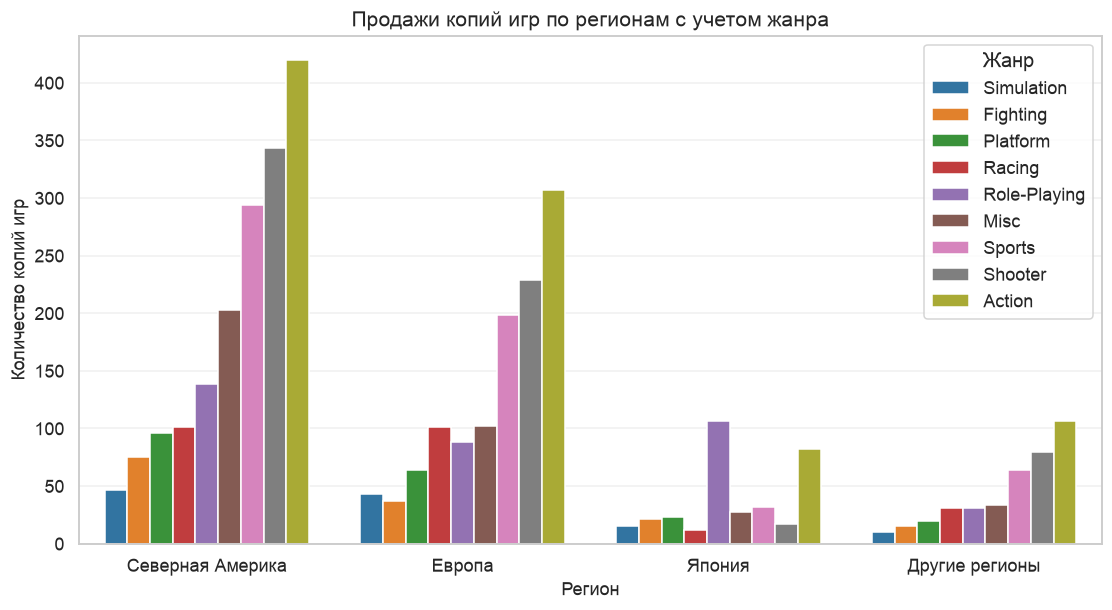

In [44]:
# Построим барплот продаж копий игр по регионам с учетом жанра
sns.barplot(long_genre, x='region', y='total_sales', hue='genre')
plt.title('Продажи копий игр по регионам с учетом жанра')
plt.xlabel('Регион')
plt.ylabel('Количество копий игр')
plt.legend(title='Жанр')
plt.xticks(ticks=range(4), labels=['Северная Америка', 'Европа', 'Япония', 'Другие регионы'])
plt.show()

**Вывод:**
- В Северной Америки популярны следующие жанры: Action, Shooter, Sports, Misc и Role-Playing.
- В Европе явные лидеры по популярности следующие жанры: Action, Shooter, Sports. Также стоит отметить жанры: Misc, Racing и Role-Playing.
- В Японии явными лидерам являются: Role-Playing и Action.
- В других регионах явные лидеры по популярности следующие жанры: Action, Shooter, Sports. Также стоит отметить жанры: Misc, Racing и Role-Playing.

#### 3. Посмотрим на влияние рейтинга ESRB на продажи в разных регионах.

In [45]:
rating_per_region = (filter_data
                       .groupby('rating')
                       .agg(total_sales_na=('na_sales', 'sum'),
                            total_sales_eu=('eu_sales', 'sum'),
                            total_sales_jp=('jp_sales', 'sum'),
                            total_sales_other=('other_sales', 'sum')
                           )
                       .reset_index()
                       .sort_values('total_sales_na')
                       )

long_rating = pd.wide_to_long(rating_per_region,
                             stubnames='total_sales',
                             i='rating',
                             j='region',
                             sep='_',
                             suffix='.+')

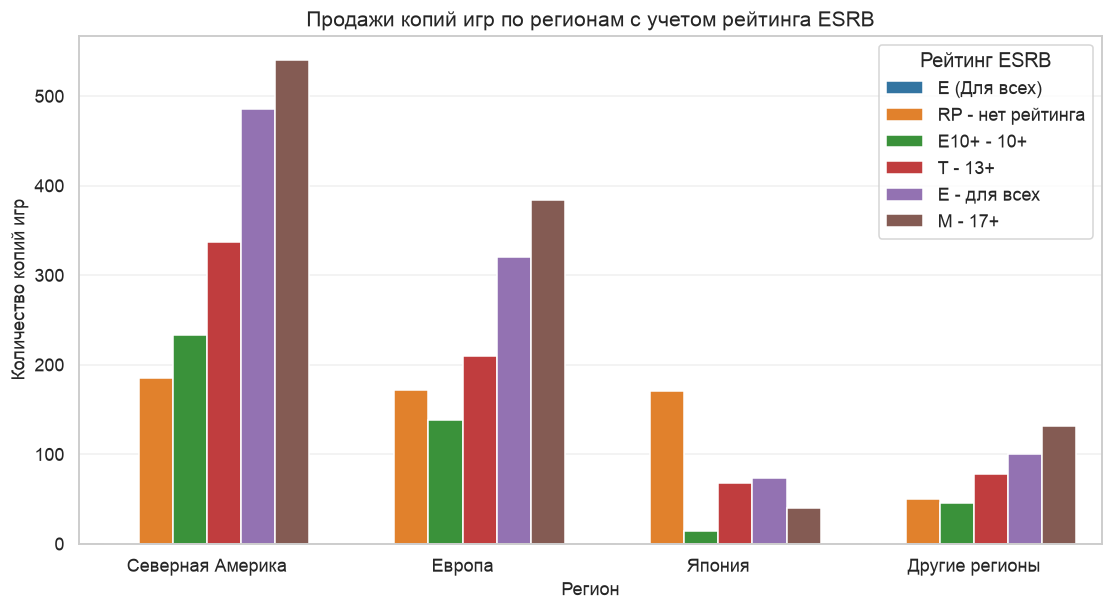

In [46]:
sns.barplot(long_rating, x='region', y='total_sales', hue='rating')
plt.title('Продажи копий игр по регионам с учетом рейтинга ESRB')
plt.xlabel('Регион')
plt.ylabel('Количество копий игр')
plt.legend(title='Рейтинг ESRB')
plt.xticks(ticks=range(4), labels=['Северная Америка', 'Европа', 'Япония', 'Другие регионы'])
plt.show()

**Вывод:**
- В Северной Америке, Европе и других регионах пользуются популярностью игры с рейтингами "17+", "для всех" и "13+".
- В Японии наиболее популярны игры без рейтинга. Возможно это связано с законодательством.

## Проверка гипотез
Проверим следующие гипотезы:
1. Средние пользовательские рейтинги платформ Xbox One и PC одинаковые;
2. Средние пользовательские рейтинги жанров Action (англ. «действие», экшен-игры) и Sports (англ. «спортивные соревнования») разные.

### 1. Средние пользовательские рейтинги платформ Xbox One и PC одинаковые.
**H0:** Средние пользовательские рейтинги платформ Xbox One и PC - ОДИНАКОВЫЕ.  
**H1:** Средние пользовательские рейтинги платформ Xbox One и PC - РАЗНЫЕ.



In [47]:
# Отберем оценки пользователей для 'XOne', 'PC'
user_score_pc_xone = filter_data.query("platform in ['XOne', 'PC'] ")[['user_score', 'platform']]
user_score_pc_xone = user_score_pc_xone.dropna()

In [48]:
# Данные для PC
user_score_pc = user_score_pc_xone.query("platform == 'PC'")['user_score']

In [49]:
# Данные для XOne
user_score_xone = user_score_pc_xone.query("platform == 'XOne'")['user_score']

In [50]:
# Проверим данные user_score_xone на нормальность распределения
pg.normality(user_score_xone)

,W,pval,normal
user_score,0.955056,0.000015,False


In [51]:
# Проверим данные user_score_pc на нормальность распределения
pg.normality(user_score_pc)

,W,pval,normal
user_score,0.923593,1.898906e-16,False


In [52]:
# Проверим данные на равенство дисперсий
pg.homoscedasticity(user_score_pc_xone,
                    dv='user_score',
                    group='platform',
                    nan_policy='omit')

,W,pval,equal_var
levene,2.428718,0.119551,True


Проведем ttest с уровнем значимости 0.05

In [53]:
pg.ttest(user_score_xone, user_score_pc)

,T,dof,alternative,p_val,CI95,cohen_d,power,BF10
T_test,-2.047035,333.896738,two-sided,0.041437,"[-0.48, -0.01]",0.165216,0.491629,0.726


T-test показал, что мы можем отвергнуть Н0 на уровне значимости 0.05.  
Построим график распределения пользовательских оценок по платформам

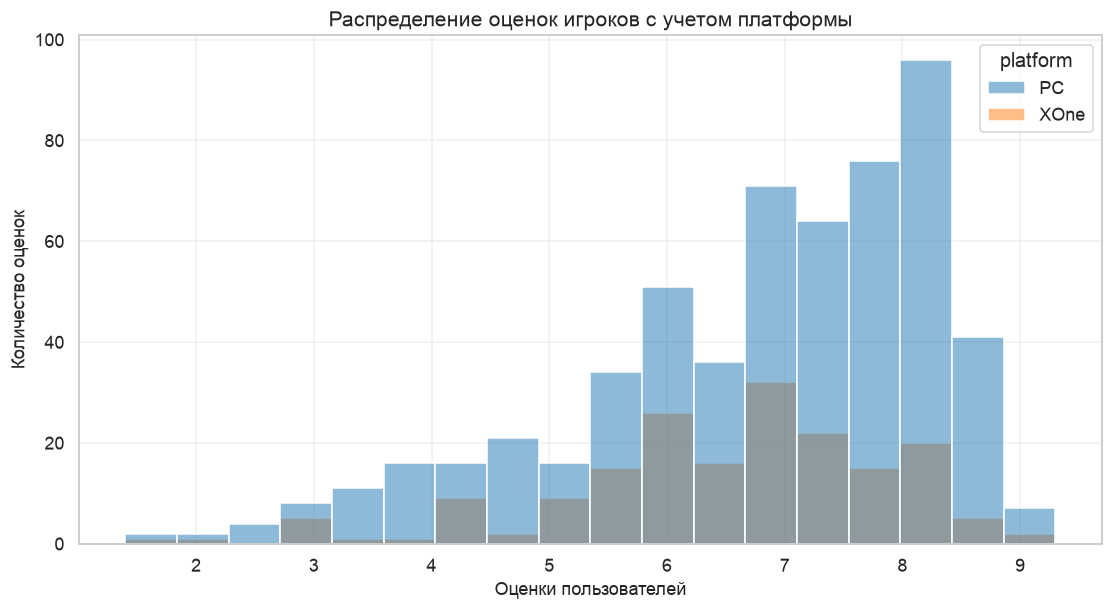

In [54]:
sns.histplot(data=user_score_pc_xone, x='user_score', hue='platform')
plt.title('Распределение оценок игроков с учетом платформы')
plt.xlabel('Оценки пользователей')
plt.ylabel('Количество оценок')
plt.show()

**Вывод:** мы отвергаем Н0: "Средние пользовательские рейтинги платформ Xbox One и PC - ОДИНАКОВЫЕ" в пользу Н1: "Средние пользовательские рейтинги платформ Xbox One и PC - РАЗНЫЕ" на уровне значимости 0.05.

### 2. Средние пользовательские рейтинги жанров Action (англ. «действие», экшен-игры) и Sports (англ. «спортивные соревнования») разные.

**Н0:** Средние пользовательские рейтинги жанров Action и Sports - ОДИНАКОВЫЕ.  
**Н1:** Средние пользовательские рейтинги жанров Action и Sports - РАЗНЫЕ.

In [55]:
# Отберем данные по жанрам Action и Sports
user_score_action_sports = filter_data.query("genre in ['Action', 'Sports']")[['user_score', 'genre']]
user_score_action_sports = user_score_action_sports.dropna()

In [56]:
user_score_action = user_score_action_sports.query("genre == 'Action'")['user_score']

In [57]:
user_score_sports = user_score_action_sports.query("genre == 'Sports'")['user_score']

In [58]:
# Проверим данные user_score_action на нормальность распределения
pg.normality(user_score_action)

,W,pval,normal
user_score,0.93007,2.738774e-22,False


In [59]:
# Проверим данные user_score_action на нормальность распределения
pg.normality(user_score_sports)

,W,pval,normal
user_score,0.940545,8.819764e-14,False


In [60]:
# Проверим данные на равенство дисперсий
pg.homoscedasticity(user_score_action_sports,
                    dv='user_score',
                    group='genre',
                    nan_policy='omit')

,W,pval,equal_var
levene,38.118978,8.377563e-10,False


Проведем ttest с уровнем значимости 0.05 и поправкой Уэлча

In [61]:
pg.ttest(x=user_score_sports, y=user_score_action, correction=True)

,T,dof,alternative,p_val,CI95,cohen_d,power,BF10
T_test,-7.645134,855.436669,two-sided,5.605531e-14,"[-0.8, -0.48]",0.439081,1.0,1.349e+11


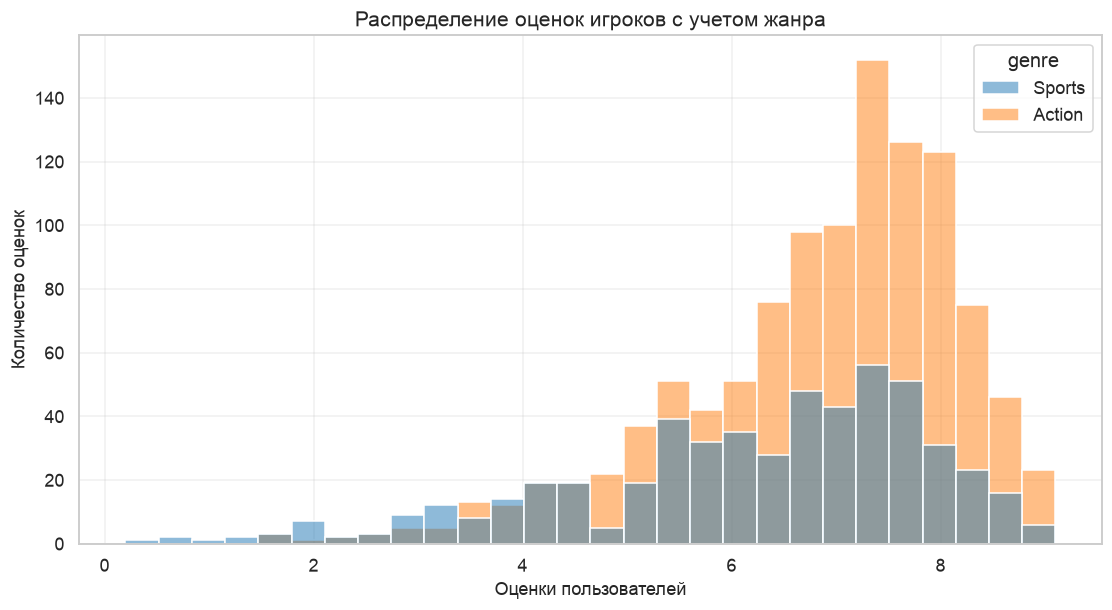

In [62]:
# Построим график распределения пользовательских оценок с учетм жанра
sns.histplot(data=user_score_action_sports, x='user_score', hue='genre')
plt.title('Распределение оценок игроков с учетом жанра')
plt.xlabel('Оценки пользователей')
plt.ylabel('Количество оценок')
plt.show()

**Вывод:** мы отвергаем Н0: "Средние пользовательские рейтинги жанров Action и Sports - ОДИНАКОВЫЕ" в пользу Н1: "Средние пользовательские рейтинги жанров Action и Sports - РАЗНЫЕ" на уровне значимости 5%.
